1. Ficha Técnica y Origen de los Datos
Fuente del Dataset: https://www.kaggle.com/datasets/gregorut/videogamesales

Licencia: CC0 1.0 Universal (Public Domain Dedication). Permite uso comercial, modificación y distribución sin restricciones legales.

Contexto de Negocio: El mercado global de videojuegos es altamente competitivo. Analizar el rendimiento histórico de ventas permite a estudios y distribuidores evaluar el riesgo comercial de un nuevo título basándose en factores clave de lanzamiento (plataforma, género, empresa editora y ventana temporal).

2. Planteamiento del Problema
Tarea de ML: Clasificación Binaria supervisada (target in {0, 1}).
Variable Objetivo: is_hit (Global_Sales >= 0.5 M).
Prevención de Data Leakage (Fuga de Información): Las variables NA_Sales, EU_Sales, JP_Sales y Other_Sales se eliminan obligatoriamente de la matriz de características X. Si se mantuvieran, el modelo aprendería a sumar subcomponentes exactos de las ventas en lugar de predecir el éxito comercial a partir de variables a priori (plataforma, distribuidor, género y año).

======================================================================
AUDITORÍA INICIAL DEL DATASET: vgsales.csv
======================================================================
- Dimensiones originales: 16,598 filas × 11 columnas
- Registros duplicados exactos: 0 filas (0.00%)
- Nulos por columna:
    * Rank:           0 (0.00%)
    * Name:           0 (0.00%)
    * Platform:       0 (0.00%)
    * Year:         271 (1.63%)
    * Genre:          0 (0.00%)
    * Publisher:     58 (0.35%)
    * NA_Sales:       0 (0.00%)
    * EU_Sales:       0 (0.00%)
    * JP_Sales:       0 (0.00%)
    * Other_Sales:    0 (0.00%)
    * Global_Sales:   0 (0.00%)

- Distribución preliminar del Target (is_hit = Global_Sales >= 0.5M):
    * Clase 0 (< 0.5M ventas): 12,185 registros (73.41%)
    * Clase 1 (>= 0.5M ventas):  4,413 registros (26.59%)
- Balance de Clase: Desbalance moderado (~1:2.76).
======================================================================

5 Decisiones de Preparación Justificadas:
    1. Creación del Target Binario y Eliminación de Fugas de Información (Data Leakage)
    
    Acción: Generar is_hit = (Global_Sales >= 0.5).astype(int) y descartar Rank, NA_Sales, EU_Sales, JP_Sales, Other_Sales y Global_Sales
    Razonamiento: Previene que el modelo acceda a información del futuro o a sumandos directos de las ventas globales durante la fase de inferencia.
    Visualización en Notebook: Gráfico de barras de frecuencias absolutas y relativas del target is_hit mostrando el desbalance de clase
    
    2. Tratamiento de Nulos en la Variable Temporal (Year)
    Acción: Filtrar y eliminar las 271 filas que presentan nulos en Year, convirtiendo el tipo de dato de float64 a int64.
    Razonamiento: Representan solo el 1.63% del volumen total. Imputarlas con la media/mediana global alteraría la distribución real del ciclo de vida de consolas obsoletas o modernas.
    Visualización en Notebook: Diagrama de barras comparativo de la distribución del nulo por año frente al mapa de calor de datos faltantes (Missingno matrix).
    
    3.Agrupación de Cardinalidad Alta en Publisher
    Acción: Mantener los 20 editores con mayor número de lanzamientos e imputar los nulos y editores minoritarios (< 1% de cuota) bajo la categoría unificada "Other_Publisher".
    Razonamiento: Existen más de 570 distribuidores, de los cuales más de 300 solo tienen 1 o 2 juegos en el dataset. Esto evita el problema de alta dimensionalidad (curse of dimensionality) y sobreajuste en modelos basados en árboles o regresión logística.
    Visualización en Notebook: Gráfico de Pareto (curva acumulada) con la cobertura de juegos por top N editores.
    
    4. Ingeniería de Características: Agrupación de Plataformas por Fabricante (Platform_Vendor)
    Acción: Crear una nueva columna categórica Platform_Vendor agrupando las plataformas en 5 grandes bloques: Nintendo, Sony, Microsoft, PC y Other.
    Razonamiento: Permite al modelo capturar patrones de ventas a nivel de ecosistema/hardware de marca, facilitando la generalización cuando una plataforma específica tiene pocos ejemplos históricos.
    Visualización en Notebook: Diagrama de barras apiladas o bivariante mostrando la tasa de éxito comercial (is_hit=1) por cada fabricante.
    
    5.Depuración de Anomalías Temporales e Históricas (Outliers de Fecha)
    Acción: Filtrar cualquier registro cuyo Year sea posterior al año de recopilación coherente del dataset (> 2017).
    Razonamiento: Existen registros erróneos generados por scraping informales (como lanzamientos con años 2020 registrados erróneamente en datasets antiguos) que sesgan la tendencia temporal de entrenamiento.
    Visualización en Notebook: Boxplot y Scatter plot de Year vs. Platform identificando valores fuera del rango operativo de cada consola.

In [13]:
import sys
sys.path.append('..') # Permitir importar desde src/

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from src.data_prep import run_data_pipeline

df = run_data_pipeline(input_path='../data/raw/vgsales.csv', output_path='../data/processed/vgsales_cleaned.csv')

EJECUTANDO PIPELINE DE PREPARACIÓN DE DATOS
- Filas iniciales: 16598 | Columnas iniciales: 11
- Duplicados exactos: 0
 [OK] Validación de Esquema con Pandera completada exitosamente.
- Artefacto guardado exitosamente en: ../data/processed/vgsales_cleaned.csv


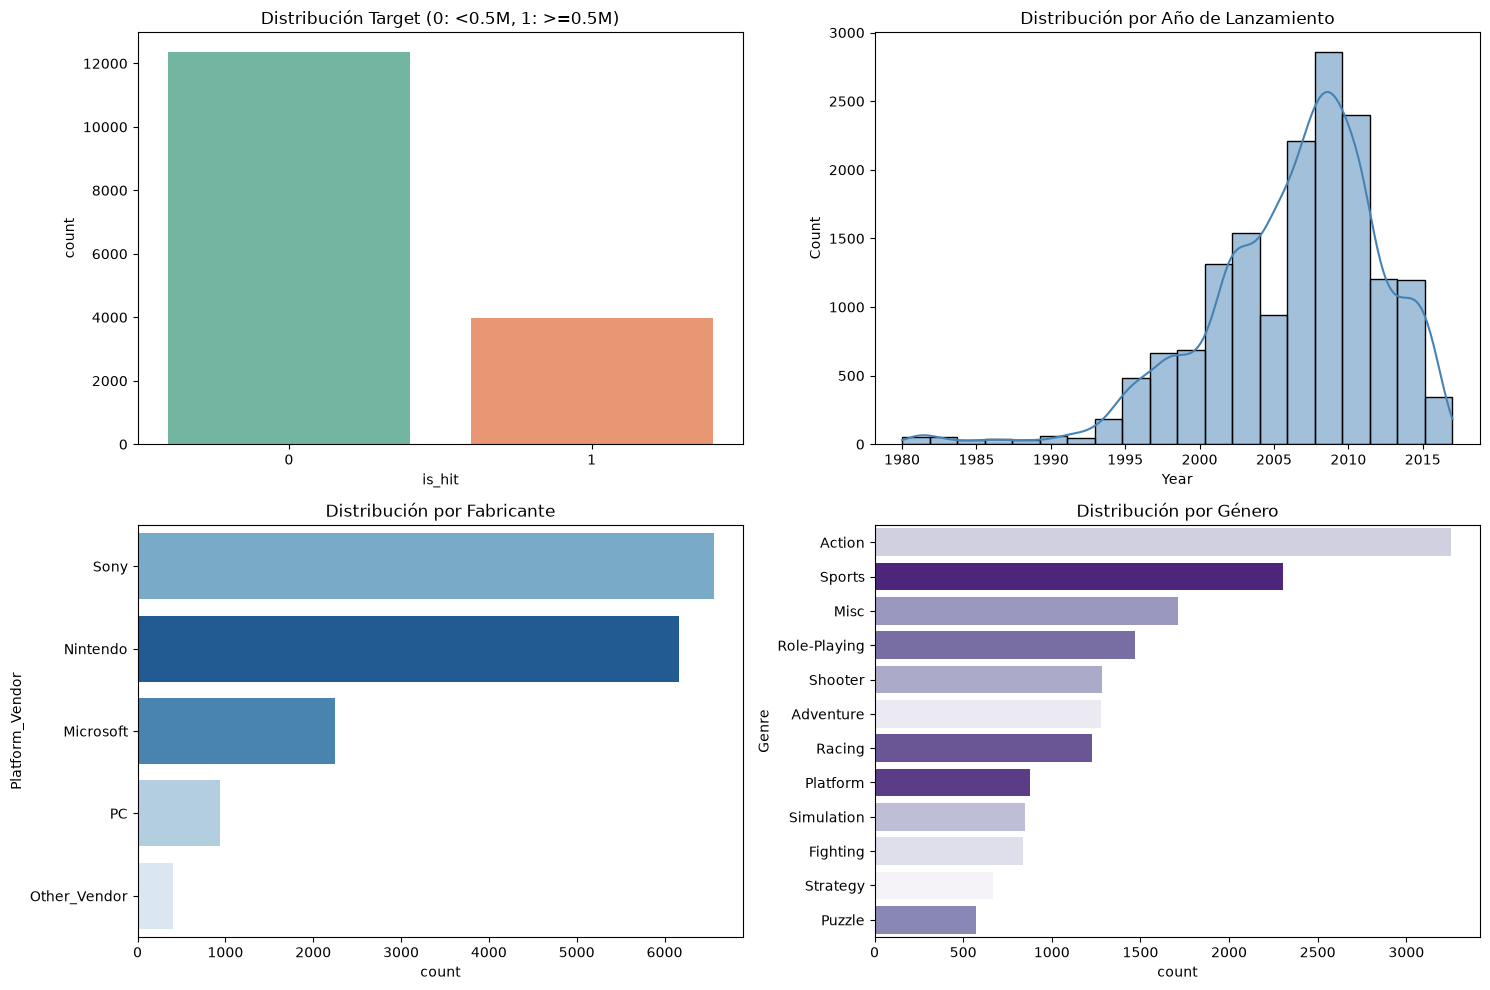

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Target: is_hit
sns.countplot(x='is_hit', data=df, ax=axes[0, 0], hue='is_hit', palette='Set2', legend=False)
axes[0, 0].set_title('Distribución Target (0: <0.5M, 1: >=0.5M)')

# Variable Temporal: Year
sns.histplot(df['Year'], bins=20, kde=True, ax=axes[0, 1], color='steelblue')
axes[0, 1].set_title('Distribución por Año de Lanzamiento')

# Platform Vendor
sns.countplot(
    y='Platform_Vendor', 
    data=df, 
    order=df['Platform_Vendor'].value_counts().index, 
    ax=axes[1, 0], 
    hue='Platform_Vendor', 
    palette='Blues_r', 
    legend=False
)
axes[1, 0].set_title('Distribución por Fabricante')

# Genre
sns.countplot(
    y='Genre', 
    data=df, 
    order=df['Genre'].value_counts().index, 
    ax=axes[1, 1], 
    hue='Genre', 
    palette='Purples_r', 
    legend=False
)
axes[1, 1].set_title('Distribución por Género')

plt.tight_layout()
plt.show()

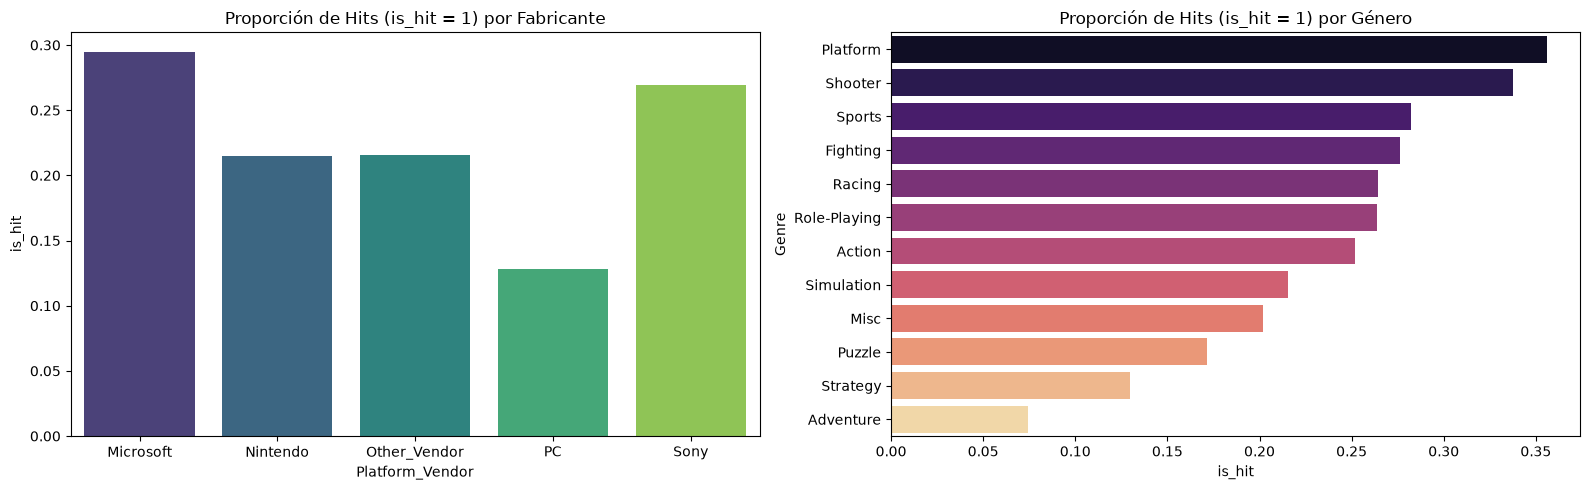

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Tasa de éxito por fabricante
vendor_hit = df.groupby('Platform_Vendor')['is_hit'].mean().reset_index()
sns.barplot(
    x='Platform_Vendor', 
    y='is_hit', 
    data=vendor_hit, 
    ax=axes[0], 
    hue='Platform_Vendor', 
    palette='viridis', 
    legend=False
)
axes[0].set_title('Proporción de Hits (is_hit = 1) por Fabricante')

# Tasa de éxito por género
genre_hit = df.groupby('Genre')['is_hit'].mean().sort_values(ascending=False).reset_index()
sns.barplot(
    x='is_hit', 
    y='Genre', 
    data=genre_hit, 
    ax=axes[1], 
    hue='Genre', 
    palette='magma', 
    legend=False
)
axes[1].set_title('Proporción de Hits (is_hit = 1) por Género')

plt.tight_layout()
plt.show()

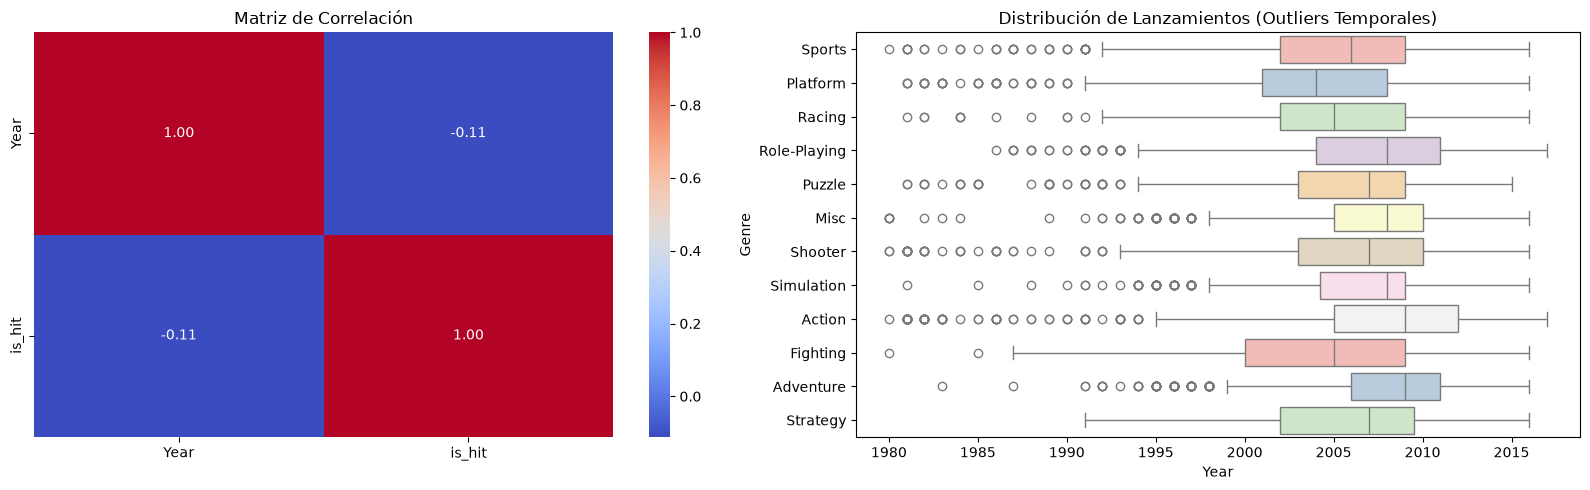

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Matriz de Correlación de Pearson
numeric_df = df.select_dtypes(include=['number'])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', ax=axes[0])
axes[0].set_title('Matriz de Correlación')

# Outliers temporales por género
sns.boxplot(
    x='Year', 
    y='Genre', 
    data=df, 
    ax=axes[1], 
    hue='Genre', 
    palette='Pastel1', 
    legend=False
)
axes[1].set_title('Distribución de Lanzamientos (Outliers Temporales)')

plt.tight_layout()
plt.show()